# SimSys Local · Fase 1 · Notebook 02
## Preprocesado, cálculo de similitudes y validación

Este notebook ejecuta paso a paso lo mismo que `main_fase1.py`, pero con explicaciones y gráficos:

1. Lectura del Excel y **preprocesado** (tipos de variable, nulos, escalado).
2. **Comprobación manual** de la fórmula de similitud sobre un par de entidades.
3. **Cálculo** de la similitud de todos los pares (≈50 M con 10.000 entidades) para las métricas *hybrid* y *volume*.
4. **Distribución** de similitudes y análisis de umbrales (base para el grafo de la fase 2).
5. **Validación** contra el segmento simulado: intra/inter, Precision@10, matriz segmento × segmento.
6. **Ejemplos** cualitativos y consulta de los más similares a cualquier entidad.

> Ejecuta el notebook una vez con `PROYECTO = "CLIENTES"` y otra con `PROYECTO = "LOCALES"`.
> Requiere haber generado los Excel (notebook 01 o `python generar_datos.py`).

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from simsys import GenericSimilaritySystem, LocalStage
from simsys.evaluation import (distribution_summary, histogram_table, validate_against_segments,
                               top_k_from_pairs, top_k_similares)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

## 0. Parámetros

| Parámetro | Descripción |
|---|---|
| `PROYECTO` | `"CLIENTES"` o `"LOCALES"` (definidos en `config.py`) |
| `MUESTRA` | `None` para usar todo, o un número (p. ej. `2000`) para una prueba rápida |
| `METRICAS` | `["hybrid", "volume"]` o solo una |
| `RAM_GB` | RAM que puede usar el cálculo por bloques |
| `VERBOSE` | Log detallado del preprocesado y del cálculo |

In [2]:
PROYECTO = "CLIENTES"
MUESTRA = None
METRICAS = ["hybrid", "volume"]
RAM_GB = config.RAM_GB
VERBOSE = True

cfg = config.PROYECTOS[PROYECTO]
ID = cfg["id"]
EJE = "General"
stage = LocalStage(config.STAGE_DIR)

df = GenericSimilaritySystem.read_excel(cfg["fichero"], cfg["hoja"], sample=MUESTRA)
print(f"{PROYECTO}: {df.shape[0]:,} entidades x {df.shape[1]} columnas")
print("Normalización por métrica:", {m: config.METRICAS[m]["normalizacion"] for m in METRICAS})

CLIENTES: 10,000 entidades x 40 columnas
Normalización por métrica: {'hybrid': 'StandardScaler', 'volume': 'MinMaxScaler'}


## 1. Preprocesado

El `DataPreprocessor` hace tres cosas:

1. **Detecta el tipo** de cada variable: `numeric`, `categorical` o `boolean`.
2. **Rellena nulos**: mediana en numéricas, `0` en booleanas y la categoría `"__NA__"` en categóricas.
3. **Escala** las numéricas con el método configurado para cada métrica (`config.METRICAS`).

Se crea un sistema por métrica porque cada una usa una normalización distinta, igual que en producción,
donde hay un procedimiento almacenado por métrica.

In [3]:
sistemas = {}
for metrica in METRICAS:
    s = GenericSimilaritySystem(project_name=PROYECTO, stage=stage, distance_metrics=[metrica],
                                ram_gb=RAM_GB, max_pairs_per_file=config.MAX_PARES_POR_FICHERO,
                                verbose=VERBOSE)
    s.preprocess_data(df, exclude_variables=cfg["excluir"],
                      normalization=config.METRICAS[metrica]["normalizacion"], entity_id_column=ID)
    s.save_processed_data(config.PROCESSED_DIR, suffix=metrica.upper())
    sistemas[metrica] = s


🚀 INICIANDO PREPROCESADO DE DATOS 🚀
  Normalización: StandardScaler
  Métricas: hybrid
  Columna ID: PLAYER_ID
  Variables excluidas: ['SEGMENTO_SIMULADO']
  Dimensiones entrada: 10,000 entidades x 40 columnas

FASE 1: DETECCIÓN DE TIPOS DE VARIABLES
  Total variables analizadas: 38
  - numeric: 25
  - categorical: 9
  - boolean: 4

FASE 2: PREPROCESAMIENTO DE DATOS
  Columnas no usadas (excluidas u 'other'): ['SEGMENTO_SIMULADO']
  [NaN] EDAD: 192 valores -> mediana (35.00)
  [NaN] PCT_APUESTAS_LIVE: 387 valores -> mediana (0.20)
  [NaN] BALANCE: 198 valores -> mediana (11.21)
  [NaN] OPEN_RATE_EMAIL: 1959 valores -> mediana (0.30)
  Total NaN rellenados: 6,342
  Dimensiones finales: 10,000 entidades x 38 variables
  Memoria: 2.23 MB

FASE 3: NORMALIZACIÓN DE DATOS
  StandardScaler aplicado a 25 columnas numéricas



🚀 INICIANDO PREPROCESADO DE DATOS 🚀
  Normalización: MinMaxScaler
  Métricas: volume
  Columna ID: PLAYER_ID
  Variables excluidas: ['SEGMENTO_SIMULADO']
  Dimensiones entrada: 10,000 entidades x 40 columnas

FASE 1: DETECCIÓN DE TIPOS DE VARIABLES
  Total variables analizadas: 38
  - numeric: 25
  - categorical: 9
  - boolean: 4

FASE 2: PREPROCESAMIENTO DE DATOS
  Columnas no usadas (excluidas u 'other'): ['SEGMENTO_SIMULADO']
  [NaN] EDAD: 192 valores -> mediana (35.00)
  [NaN] PCT_APUESTAS_LIVE: 387 valores -> mediana (0.20)
  [NaN] BALANCE: 198 valores -> mediana (11.21)
  [NaN] OPEN_RATE_EMAIL: 1959 valores -> mediana (0.30)
  Total NaN rellenados: 6,342
  ⚠️  'volume' usa la norma L2 (-1000 y +1000 pesan igual). Variables con negativos antes de escalar: ['NGR_SPORTS', 'NGR_CASINO', 'NGR_30D']
  Dimensiones finales: 10,000 entidades x 38 variables
  Memoria: 2.23 MB

FASE 3: NORMALIZACIÓN DE DATOS
  MinMaxScaler aplicado a 25 columnas numéricas
  ⚠️  Con 'volume', MinMaxScaler c

In [4]:
prep = sistemas[METRICAS[0]].preprocessor
tabla_vars = prep.variable_types_table()
print(tabla_vars["TIPO"].value_counts().to_string())
tabla_vars

TIPO
numeric        25
categorical     9
boolean         4


,VARIABLE,TIPO,NULOS,PCT_NULOS,VALORES_UNICOS,IMPUTACION
0,GENERO,categorical,0,0.0000,2,
1,EDAD,numeric,192,0.0192,62,35.0
2,PROVINCIA,categorical,94,0.0094,20,__NA__
3,CANAL_ADQUISICION,categorical,0,0.0000,5,
4,DISPOSITIVO_PRINCIPAL,categorical,0,0.0000,3,
5,MULTICANAL,boolean,0,0.0000,2,
6,PRODUCTO_FAVORITO,categorical,0,0.0000,3,
7,DEPORTE_FAVORITO,categorical,3226,0.3226,5,__NA__
8,FRANJA_HORARIA_FAVORITA,categorical,0,0.0000,4,
9,METODO_DEPOSITO,categorical,286,0.0286,5,__NA__


### Efecto del escalado sobre algunas variables numéricas

In [5]:
num_cols = prep.columns_of_type("numeric")[:6]
antes = prep.processed_data_before_scaling[num_cols].describe().T[["mean", "std", "min", "max"]].add_prefix("antes_")
resultados_escalado = [antes]
for m, s in sistemas.items():
    d = s.preprocessor.processed_data[num_cols].describe().T[["mean", "std", "min", "max"]]
    resultados_escalado.append(d.add_prefix(f"{m}_"))
pd.concat(resultados_escalado, axis=1).round(2)

,antes_mean,antes_std,antes_min,antes_max,hybrid_mean,hybrid_std,hybrid_min,hybrid_max,volume_mean,volume_std,volume_min,volume_max
EDAD,36.59,11.07,18.0,84.0,-0.0,1.0,-1.68,4.28,0.28,0.17,0.0,1.0
PCT_APUESTAS_LIVE,0.23,0.19,0.0,1.0,-0.0,1.0,-1.18,3.95,0.23,0.19,0.0,1.0
DIAS_DESDE_REGISTRO,1227.23,902.61,5.0,4500.0,-0.0,1.0,-1.35,3.63,0.27,0.20,0.0,1.0
DIAS_DESDE_ULTIMO_ACCESO,36.62,86.81,0.0,720.0,-0.0,1.0,-0.42,7.87,0.05,0.12,0.0,1.0
DIAS_DESDE_ULTIMA_APUESTA,43.12,93.48,0.0,751.0,0.0,1.0,-0.46,7.57,0.06,0.12,0.0,1.0
DIAS_DESDE_ULTIMO_DEPOSITO,52.97,95.68,1.0,771.0,0.0,1.0,-0.54,7.50,0.07,0.12,0.0,1.0


## 2. Las métricas, y una comprobación manual

**Hybrid** (numéricas + categóricas):

$$S_{hybrid}(a,b) = 1 - \Big[\alpha \cdot \big(1 - \cos(a_{num}, b_{num})\big) + (1-\alpha)\cdot \tfrac{1}{p_{cat}}\textstyle\sum_j \mathbb{1}[a_j \neq b_j]\Big], \qquad \alpha = \frac{p_{num}}{p_{num}+p_{cat}}$$

- La parte numérica es la **distancia coseno**, que compara la *forma* del perfil (en qué variables destaca cada entidad).
- La parte categórica es la **distancia de Gower** para categóricas: la proporción de variables en las que no coinciden.
- Con datos estandarizados el coseno puede ser negativo, así que $S_{hybrid} \in [-1, 1]$.

**Volume** (solo numéricas):

$$S_{volume}(a,b) = \frac{\min(\lVert a\rVert, \lVert b\rVert)}{\max(\lVert a\rVert, \lVert b\rVert)} \in [0, 1]$$

Compara la **magnitud** global (lo "grande" que es cada entidad), no su forma.

Ambas se guardan como enteros ×100. Antes de lanzar el cálculo masivo, calculamos a mano la similitud de un par
concreto; al final del notebook comprobaremos que coincide con lo que guarda el sistema.

In [6]:
def similitud_manual(sistema, a_id, b_id, metrica):
    p = sistema.preprocessor
    X = p.processed_data
    num = p.columns_of_type("numeric")
    cat = p.columns_of_type("categorical", "boolean")
    a_num, b_num = X.loc[a_id, num].to_numpy(float), X.loc[b_id, num].to_numpy(float)
    if metrica == "hybrid":
        alpha = len(num) / (len(num) + len(cat))
        na, nb = np.linalg.norm(a_num), np.linalg.norm(b_num)
        cos = a_num @ b_num / (na * nb) if na * nb else 0.0
        d_cat = np.mean(X.loc[a_id, cat].astype(str).to_numpy() != X.loc[b_id, cat].astype(str).to_numpy())
        s = 1 - (alpha * (1 - cos) + (1 - alpha) * d_cat)
        detalle = dict(alpha=round(alpha, 3), coseno=round(float(cos), 4), gower_cat=round(float(d_cat), 4))
    else:
        na, nb = np.linalg.norm(a_num), np.linalg.norm(b_num)
        s = min(na, nb) / max(na, nb) if max(na, nb) else 1.0
        detalle = dict(norma_a=round(float(na), 4), norma_b=round(float(nb), 4))
    return int(np.clip(np.rint(s * 100), -100, 100)), detalle

rng = np.random.default_rng(1)
par = rng.choice(df[ID].to_numpy(), 2, replace=False)
a_id, b_id = int(par[0]), int(par[1])
manual = {}
for m, s in sistemas.items():
    manual[m] = similitud_manual(s, a_id, b_id, m)
    print(f"{m:7s} -> S({a_id}, {b_id}) = {manual[m][0]}   {manual[m][1]}")
df.set_index(ID).loc[[a_id, b_id]].T

hybrid  -> S(104732, 105119) = 58   {'alpha': 0.658, 'coseno': 0.6841, 'gower_cat': 0.6154}
volume  -> S(104732, 105119) = 93   {'norma_a': 0.6577, 'norma_b': 0.7053}


PLAYER_ID,104732,105119
SEGMENTO_SIMULADO,Apostador deportivo casual,Nuevo registro
GENERO,M,F
EDAD,30.0,26.0
PROVINCIA,Las Palmas,Asturias
CANAL_ADQUISICION,TV / Patrocinio,Afiliados
DISPOSITIVO_PRINCIPAL,App móvil,App móvil
MULTICANAL,0,0
PRODUCTO_FAVORITO,Poker,Sports
DEPORTE_FAVORITO,Fútbol,Fútbol
FRANJA_HORARIA_FAVORITA,Tarde,Mañana


## 3. Cálculo de todos los pares

Para `n` entidades hay `n(n−1)/2` pares (≈50 M con 10.000). La matriz completa en `float32` ocuparía
~400 MB, y sus intermedios varias veces más. Por eso el cálculo se hace **por bloques de filas**:

- el tamaño de bloque se ajusta a `RAM_GB` y a un máximo de pares por fichero;
- de cada bloque solo se guarda el **triángulo superior** (cada par una vez);
- cada bloque se escribe como un parquet `ENTITY_A, ENTITY_B, SIMILARITY` en
  `output/stage/<PROYECTO>/<metrica>/<eje>/yyyy/mm/dd/`, con la misma estructura que el almacenamiento en la nube.

El eje `General` usa todas las variables (`"*"`). En fases posteriores se podrán definir ejes temáticos en `config.py`.

In [7]:
resultados = {}
for metrica, s in sistemas.items():
    t0 = time.time()
    res = s.add_axis(EJE, cfg["ejes"][EJE])
    resultados[metrica] = res[metrica]
    print(f"⏱ {metrica}: {time.time() - t0:.1f}s\n")

pd.DataFrame([{k: v for k, v in r.items() if k != "histograma"} for r in resultados.values()])


Calculando eje GENERAL (38 variables)
  Entidades: 10,000 | Pares a calcular: 49,995,000
  Numéricas: 25 | Categóricas/booleanas: 13 | α (peso numéricas) = 0.658
  RAM configurada: 2.0 GB -> 6 bloques/ficheros


    [hybrid] bloque 1/6 filas 0-1,055 -> 9,992,960 pares ✓


    [hybrid] bloque 2/6 filas 1,055-2,253 -> 9,997,909 pares ✓


    [hybrid] bloque 3/6 filas 2,253-3,674 -> 9,998,156 pares ✓


    [hybrid] bloque 4/6 filas 3,674-5,526 -> 9,999,874 pares ✓


    [hybrid] bloque 5/6 filas 5,526-9,526 -> 9,894,000 pares ✓
    [hybrid] bloque 6/6 filas 9,526-9,999 -> 112,101 pares ✓
  ✅ hybrid: 49,995,000 pares en 13.0s
⏱ hybrid: 13.0s


Calculando eje GENERAL (38 variables)
  Entidades: 10,000 | Pares a calcular: 49,995,000
  Numéricas: 25 | Categóricas/booleanas: 13 | α (peso numéricas) = 0.658
  RAM configurada: 2.0 GB -> 6 bloques/ficheros


... (2 outputs left out)

    [volume] bloque 3/6 filas 2,253-3,674 -> 9,998,156 pares ✓


    [volume] bloque 4/6 filas 3,674-5,526 -> 9,999,874 pares ✓


    [volume] bloque 5/6 filas 5,526-9,526 -> 9,894,000 pares ✓
    [volume] bloque 6/6 filas 9,526-9,999 -> 112,101 pares ✓
  ✅ volume: 49,995,000 pares en 6.6s
⏱ volume: 6.7s



,eje,metrica,entidades,pares,ficheros,segundos,alpha,n_numericas,n_categoricas,carpeta
0,General,hybrid,10000,49995000,6,13.0,0.6579,25,13,./output/stage/CLIENTE...
1,General,volume,10000,49995000,6,6.6,0.6579,25,13,./output/stage/CLIENTE...


### Comprobación: ¿lo guardado coincide con el cálculo manual?

In [8]:
def similitud_guardada(metrica, a, b):
    for part in stage.iter_parts(PROYECTO, metrica, EJE):
        m = ((part["ENTITY_A"] == a) & (part["ENTITY_B"] == b)) | ((part["ENTITY_A"] == b) & (part["ENTITY_B"] == a))
        if m.any():
            return int(part.loc[m, "SIMILARITY"].iloc[0])

for m in METRICAS:
    guardada = similitud_guardada(m, a_id, b_id)
    ok = "✅" if abs(guardada - manual[m][0]) <= 1 else "❌"
    print(f"{m:7s} manual={manual[m][0]:4d}  guardada={guardada:4d}  {ok}")
print("\n(±1 de tolerancia por redondeo float32 vs float64)")

hybrid  manual=  58  guardada=  58  ✅


volume  manual=  93  guardada=  93  ✅

(±1 de tolerancia por redondeo float32 vs float64)


## 4. Distribución de similitudes y umbrales

La distribución se ha acumulado durante el cálculo, así que no hace falta releer los 50 M de pares.

La curva de umbrales es la base de la **fase 2**: para construir el grafo hay que decidir a partir de qué
similitud dos entidades quedan conectadas. Un umbral demasiado alto deja nodos aislados; uno demasiado bajo,
un grafo tan denso que no tiene comunidades.

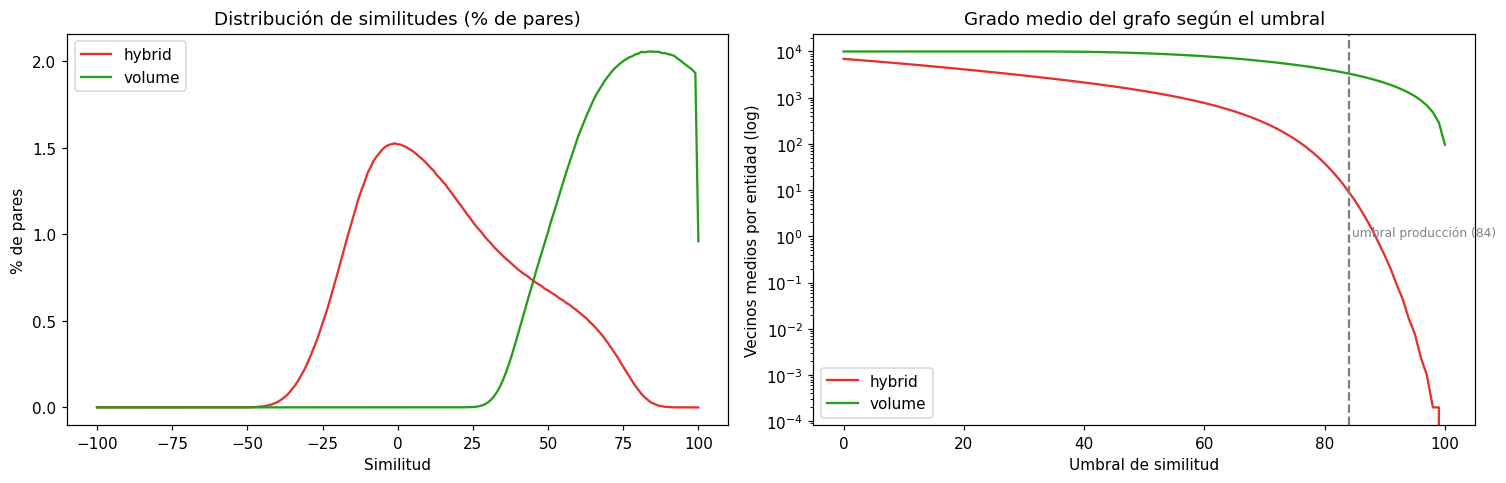

In [9]:
valores = np.arange(-100, 101)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colores = {"hybrid": "#E33130", "volume": "#249D1A"}

for m, r in resultados.items():
    h = r["histograma"]
    axes[0].plot(valores, 100 * h / h.sum(), label=m, color=colores[m])
axes[0].set_title("Distribución de similitudes (% de pares)")
axes[0].set_xlabel("Similitud"); axes[0].set_ylabel("% de pares"); axes[0].legend()

n = resultados[METRICAS[0]]["entidades"]
umbrales = np.arange(0, 101)
for m, r in resultados.items():
    h = r["histograma"]
    pares_sobre = np.array([h[valores >= u].sum() for u in umbrales])
    axes[1].plot(umbrales, 2 * pares_sobre / n, label=m, color=colores[m])
axes[1].set_yscale("log")
axes[1].axvline(84, ls="--", c="grey"); axes[1].text(84.5, 1, "umbral producción (84)", fontsize=8, color="grey")
axes[1].set_title("Grado medio del grafo según el umbral")
axes[1].set_xlabel("Umbral de similitud"); axes[1].set_ylabel("Vecinos medios por entidad (log)")
axes[1].legend()
plt.tight_layout(); plt.show()

In [10]:
pd.concat({m: distribution_summary(r["histograma"]).set_index("METRICA")["VALOR"]
           for m, r in resultados.items()}, axis=1)

,hybrid,volume
METRICA,,
Pares totales,4.999500e+07,4.999500e+07
Media,1.621000e+01,7.392000e+01
Desviación típica,2.652000e+01,1.623000e+01
Mínimo,-5.800000e+01,1.800000e+01
Máximo,9.900000e+01,1.000000e+02
Percentil 1,-3.100000e+01,3.800000e+01
Percentil 5,-2.200000e+01,4.500000e+01
Percentil 25,-4.000000e+00,6.200000e+01
Percentil 50,1.300000e+01,7.500000e+01


**Cómo leerlo.** *Hybrid* reparte las similitudes en un rango amplio (incluidos negativos), así que discrimina mucho.
*Volume* las concentra en valores altos porque muchas entidades tienen "tamaños" parecidos. Con *hybrid*,
el umbral 84 heredado de producción deja pocos vecinos por entidad: habrá que analizarlo en la fase 2.

## 5. Validación contra el segmento simulado

Como los datos son sintéticos, conocemos el perfil real de cada entidad. Si el sistema funciona:

- la similitud media **intra-segmento** debe ser mayor que la **inter-segmento**;
- los vecinos más similares de una entidad deben ser, sobre todo, de su mismo segmento.

**Precision@k**: para una muestra de 300 entidades, el % de sus k = 10 vecinos más similares que comparten segmento.
La referencia es lo que saldría **al azar**: $\frac{n_s - 1}{n - 1}$ para una entidad del segmento $s$.

In [11]:
ejemplos = np.random.default_rng(7).choice(df[ID].to_numpy(), size=3, replace=False)
segmentos = df.set_index(ID)[cfg["columna_validacion"]]

validaciones = {}
for m in METRICAS:
    t0 = time.time()
    validaciones[m] = validate_against_segments(stage, PROYECTO, m, EJE, segmentos,
                                                sample_size=300, k=10, extra_ids=ejemplos)
    print(f"{m}: validado en {time.time() - t0:.1f}s")

pd.concat({m: v["global"].set_index("METRICA")["VALOR"] for m, v in validaciones.items()}, axis=1)

hybrid: validado en 15.0s


volume: validado en 13.3s


,hybrid,volume
METRICA,,
Similitud media intra-segmento,49.5800,85.1000
Similitud media inter-segmento,9.8900,71.8000
Diferencia (intra - inter),39.6900,13.3000
Precision@10 (muestra de 300),0.8520,0.3677
Precision@10 esperada al azar,0.1552,0.1552
Mejora sobre azar (x veces),5.4900,2.3700


In [12]:
for m, v in validaciones.items():
    print(f"=== {m.upper()} ===")
    display(v["por_segmento"])

=== HYBRID ===


,SEGMENTO,N_ENTIDADES,SIM_MEDIA_INTRA,SIM_MEDIA_HACIA_OTROS,SEPARACION,PRECISION@10,BASELINE@10
0,Apostador deportivo intensivo,1018,58.21,4.69,53.52,0.9744,0.1017
1,Cliente dormido,1976,57.52,5.37,52.15,0.9831,0.1975
2,Casino live alto valor,419,51.36,3.39,47.97,0.9133,0.0418
3,Nuevo registro,1167,60.96,17.87,43.09,0.7711,0.1166
4,Jugador de slots,1573,47.70,8.03,39.67,0.8319,0.1572
5,Pokerista,495,43.31,10.58,32.73,0.8385,0.0494
6,Apostador deportivo casual,2424,43.27,14.85,28.42,0.7467,0.2423
7,Multiproducto,928,35.06,9.11,25.95,0.6913,0.0927


=== VOLUME ===


,SEGMENTO,N_ENTIDADES,SIM_MEDIA_INTRA,SIM_MEDIA_HACIA_OTROS,SEPARACION,PRECISION@10,BASELINE@10
0,Apostador deportivo intensivo,1018,89.53,61.73,27.80,0.6564,0.1017
1,Nuevo registro,1167,87.61,67.63,19.98,0.4368,0.1166
2,Casino live alto valor,419,84.85,65.02,19.83,0.1933,0.0418
3,Apostador deportivo casual,2424,86.71,71.76,14.95,0.4867,0.2423
4,Multiproducto,928,87.19,75.16,12.03,0.1957,0.0927
5,Jugador de slots,1573,87.11,76.06,11.05,0.3596,0.1572
6,Pokerista,495,86.25,76.57,9.68,0.0538,0.0494
7,Cliente dormido,1976,78.83,75.32,3.51,0.2138,0.1975


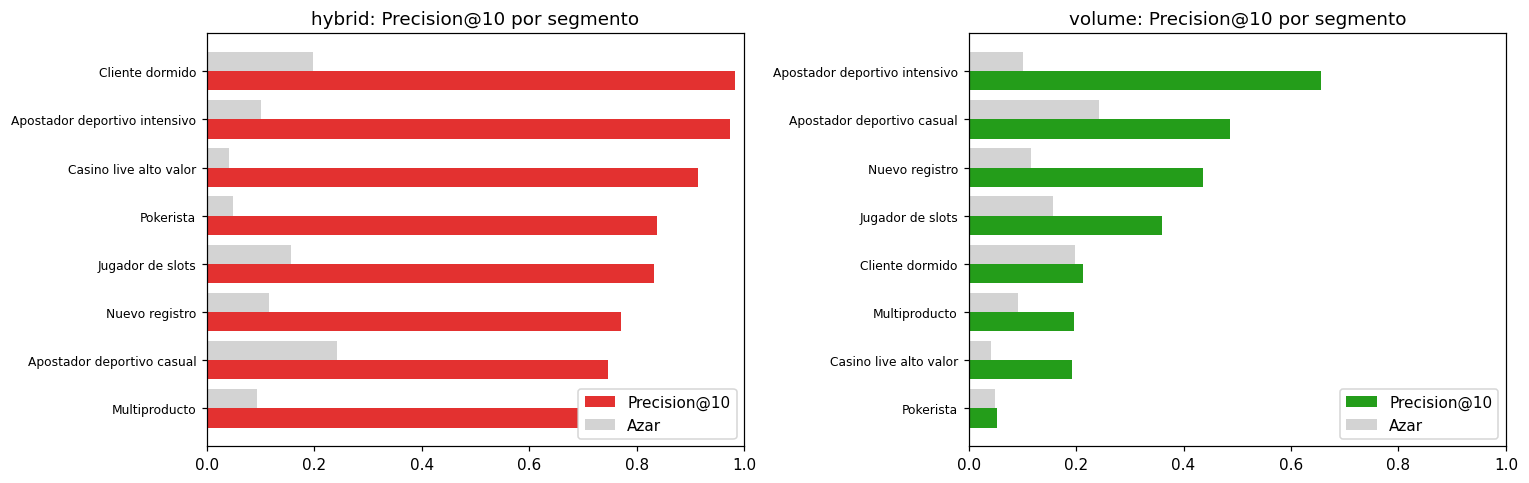

In [13]:
fig, axes = plt.subplots(1, len(METRICAS), figsize=(7 * len(METRICAS), 4.5), squeeze=False)
for ax, m in zip(axes[0], METRICAS):
    t = validaciones[m]["por_segmento"].sort_values("PRECISION@10")
    y = np.arange(len(t))
    ax.barh(y - 0.2, t["PRECISION@10"], height=0.4, label="Precision@10", color=colores[m])
    ax.barh(y + 0.2, t["BASELINE@10"], height=0.4, label="Azar", color="lightgrey")
    ax.set_yticks(y, t["SEGMENTO"], fontsize=8); ax.set_xlim(0, 1)
    ax.set_title(f"{m}: Precision@10 por segmento"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### Matriz de similitud media entre segmentos

Cada celda es la similitud media entre las entidades de dos segmentos. Una buena métrica muestra una **diagonal
destacada**. Fuera de la diagonal se ven qué perfiles "se confunden" entre sí, lo que tiene interés de negocio.

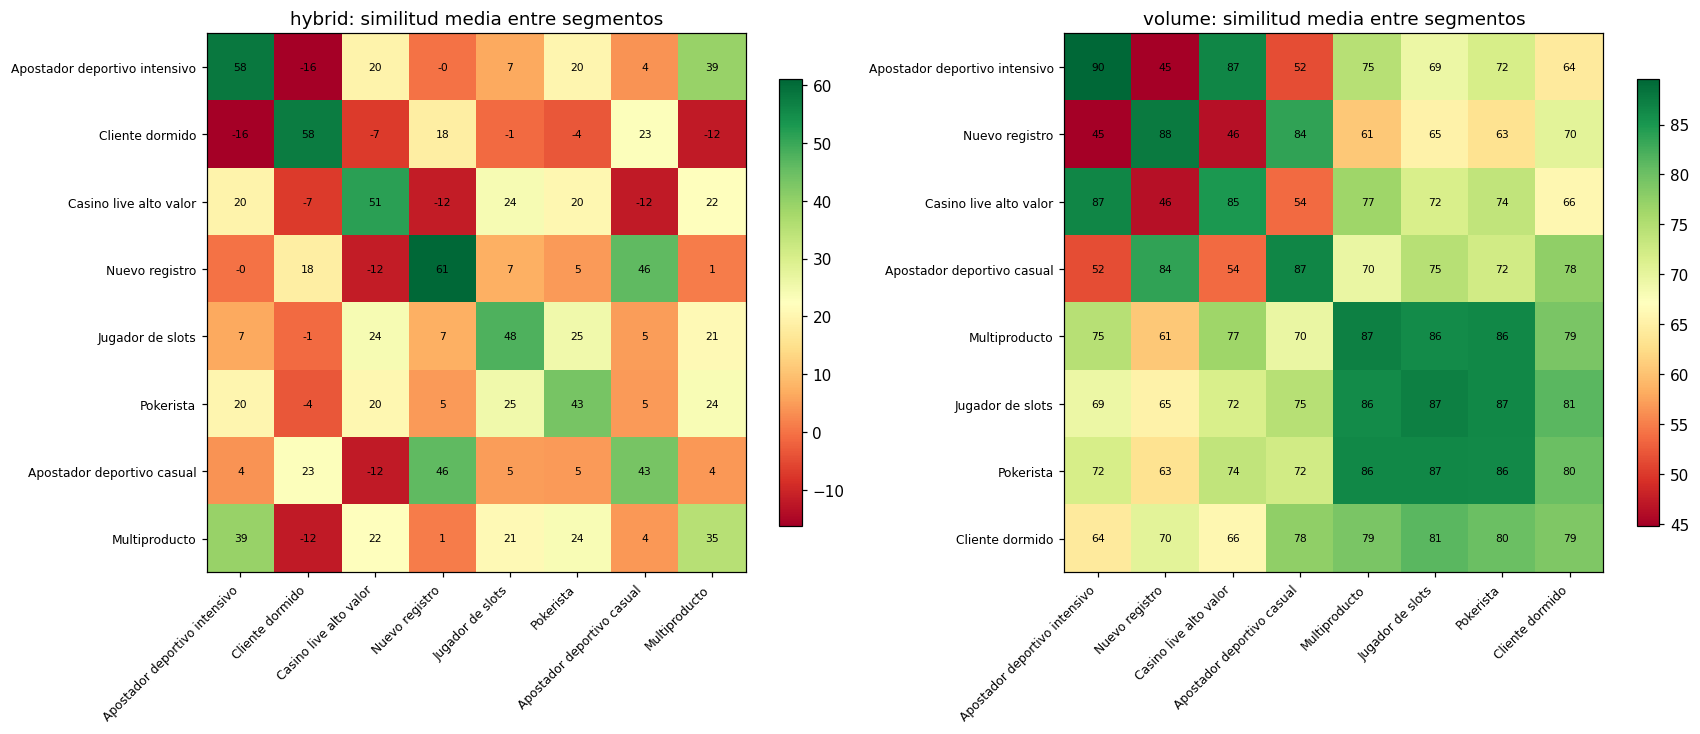

In [14]:
fig, axes = plt.subplots(1, len(METRICAS), figsize=(8 * len(METRICAS), 6.5), squeeze=False)
for ax, m in zip(axes[0], METRICAS):
    mat = validaciones[m]["matriz_segmentos"]
    orden = validaciones[m]["por_segmento"]["SEGMENTO"]
    mat = mat.loc[orden, orden]
    im = ax.imshow(mat, cmap="RdYlGn")
    ax.set_xticks(range(len(mat)), mat.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(mat)), mat.index, fontsize=8)
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, f"{mat.iat[i, j]:.0f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{m}: similitud media entre segmentos")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## 6. Ejemplos: una entidad y sus 5 más similares

In [15]:
ficha = df.set_index(ID)[cfg["columnas_ejemplo"]]

def ejemplo(m, eid, k=5):
    top = top_k_from_pairs(validaciones[m]["pares_muestra"], eid, k=k)
    ref = ficha.loc[[eid]].reset_index().assign(ROL="REFERENCIA", SIMILARITY=np.nan)
    vec = ficha.loc[top["VECINO"]].reset_index().assign(ROL="SIMILAR", SIMILARITY=top["SIMILARITY"].to_numpy())
    return pd.concat([ref, vec], ignore_index=True)[["ROL", ID, "SIMILARITY"] + cfg["columnas_ejemplo"]]

for eid in ejemplos:
    for m in METRICAS:
        print(f"--- {m.upper()} · {ID} = {eid}")
        display(ejemplo(m, eid))

--- HYBRID · PLAYER_ID = 109448


,ROL,PLAYER_ID,SIMILARITY,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO
0,REFERENCIA,109448,NaN,Nuevo registro,22.0,Sports,4,13.19,2
1,SIMILAR,102861,91.0,Nuevo registro,18.0,Sports,3,26.88,8
2,SIMILAR,109886,91.0,Nuevo registro,25.0,Sports,3,9.65,6
3,SIMILAR,106303,90.0,Nuevo registro,25.0,Sports,6,22.41,6
4,SIMILAR,106741,90.0,Nuevo registro,19.0,Sports,3,20.43,4
5,SIMILAR,101455,89.0,Nuevo registro,23.0,Sports,6,15.60,3


--- VOLUME · PLAYER_ID = 109448


,ROL,PLAYER_ID,SIMILARITY,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO
0,REFERENCIA,109448,NaN,Nuevo registro,22.0,Sports,4,13.19,2
1,SIMILAR,100130,100.0,Apostador deportivo casual,28.0,Sports,6,22.54,8
2,SIMILAR,100211,100.0,Apostador deportivo casual,22.0,Sports,7,18.34,8
3,SIMILAR,100267,100.0,Nuevo registro,27.0,Sports,8,70.63,1
4,SIMILAR,100389,100.0,Apostador deportivo casual,26.0,Sports,7,9.81,0
5,SIMILAR,100594,100.0,Apostador deportivo casual,25.0,Casino,4,66.36,11


--- HYBRID · PLAYER_ID = 106251


,ROL,PLAYER_ID,SIMILARITY,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO
0,REFERENCIA,106251,NaN,Cliente dormido,51.0,Poker,0,0.0,80
1,SIMILAR,108939,85.0,Cliente dormido,49.0,Sports,0,0.0,104
2,SIMILAR,104719,84.0,Cliente dormido,45.0,Poker,0,0.0,137
3,SIMILAR,103782,82.0,Cliente dormido,52.0,Sports,0,0.0,142
4,SIMILAR,105316,82.0,Cliente dormido,39.0,Poker,0,0.0,53
5,SIMILAR,107012,82.0,Cliente dormido,58.0,Sports,0,0.0,133


... (2 outputs left out)

--- HYBRID · PLAYER_ID = 106842


,ROL,PLAYER_ID,SIMILARITY,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO
0,REFERENCIA,106842,NaN,Apostador deportivo casual,NaN,Sports,4,8.07,18
1,SIMILAR,101555,91.0,Apostador deportivo casual,33.0,Sports,3,13.09,4
2,SIMILAR,103571,91.0,Apostador deportivo casual,35.0,Sports,4,24.70,19
3,SIMILAR,107977,91.0,Apostador deportivo casual,36.0,Sports,5,24.36,7
4,SIMILAR,105199,88.0,Apostador deportivo casual,38.0,Sports,5,49.00,20
5,SIMILAR,104954,87.0,Apostador deportivo casual,34.0,Sports,5,12.52,12


--- VOLUME · PLAYER_ID = 106842


,ROL,PLAYER_ID,SIMILARITY,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO
0,REFERENCIA,106842,NaN,Apostador deportivo casual,NaN,Sports,4,8.07,18
1,SIMILAR,100090,100.0,Apostador deportivo casual,43.0,Sports,6,135.19,5
2,SIMILAR,100193,100.0,Cliente dormido,35.0,Sports,0,0.00,177
3,SIMILAR,100212,100.0,Apostador deportivo casual,34.0,Sports,6,93.51,7
4,SIMILAR,100252,100.0,Jugador de slots,38.0,Casino,7,116.22,2
5,SIMILAR,100310,100.0,Apostador deportivo casual,33.0,Casino,4,45.06,10


### Consulta libre

Cambia `ENTIDAD` por cualquier ID para ver sus más similares. Esta función recorre todas las partes del stage,
así que tarda unos segundos.

In [16]:
ENTIDAD = int(df[ID].iloc[0])
METRICA_CONSULTA = "hybrid"
K = 10

top = top_k_similares(stage, PROYECTO, METRICA_CONSULTA, EJE, ENTIDAD, k=K)
pd.concat([ficha.loc[[ENTIDAD]].reset_index().assign(SIMILARITY=np.nan),
           ficha.loc[top["VECINO"]].reset_index().assign(SIMILARITY=top["SIMILARITY"].to_numpy())],
          ignore_index=True)

,PLAYER_ID,SEGMENTO_SIMULADO,EDAD,PRODUCTO_FAVORITO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,DIAS_DESDE_ULTIMO_ACCESO,SIMILARITY
0,100001,Jugador de slots,63.0,Casino,13,35.82,8,NaN
1,103759,Jugador de slots,50.0,Casino,8,45.57,2,89.0
2,101232,Jugador de slots,57.0,Casino,10,5.76,2,85.0
3,100617,Jugador de slots,49.0,Casino,12,12.79,4,82.0
4,109292,Jugador de slots,59.0,Casino,11,157.47,3,82.0
5,108357,Jugador de slots,61.0,Casino,12,80.23,3,79.0
6,106689,Jugador de slots,58.0,Casino,14,103.43,1,77.0
7,100827,Jugador de slots,51.0,Casino,11,129.93,1,76.0
8,102661,Jugador de slots,48.0,Casino,9,23.60,6,76.0
9,108381,Jugador de slots,51.0,Casino,15,177.93,3,76.0


## 7. Carga del resultado (equivalente al procedimiento de carga del sistema original)

`load_latest` carga la última ejecución de un eje. Con 50 M de pares es mejor filtrar por un umbral.
Esta será la entrada del grafo en la fase 2.

In [17]:
UMBRAL = 80
pares = stage.load_latest(PROYECTO, "hybrid", EJE, min_similarity=UMBRAL)
print(f"Pares con similitud >= {UMBRAL}: {len(pares):,}  "
      f"({pares.memory_usage(deep=True).sum() / 1024**2:.1f} MB)")
print(f"Entidades con al menos un vecino: {pd.unique(pares[['ENTITY_A', 'ENTITY_B']].values.ravel()).size:,} "
      f"de {len(df):,}")
pares.head()

Pares con similitud >= 80: 190,394  (1.6 MB)
Entidades con al menos un vecino: 9,011 de 10,000


,ENTITY_A,ENTITY_B,SIMILARITY
0,100001,100617,82
1,100001,101232,85
2,100001,103759,89
3,100001,109292,82
4,100002,100003,80


## 8. Conclusiones de la fase 1

- El pipeline calcula la similitud de **todos los pares** con memoria acotada y deja el resultado en disco
  con la misma estructura que la versión original.
- La implementación coincide con el cálculo manual de la fórmula.
- **Hybrid** recupera bien los perfiles latentes: Precision@10 varias veces por encima del azar y una diagonal clara
  en la matriz de segmentos.
- **Volume** aporta información de *magnitud*, pero por sí sola discrimina poco: tiene más sentido como
  complemento (p. ej., para desempatar o ponderar en la fase 3) que como métrica principal.
- El umbral de producción (84) deja pocos vecinos por entidad con datos estandarizados. Su elección es el punto de
  partida de la **fase 2** (grafo y detección de comunidades).